<h1>Project Group 30: Predicting Repeat Purchases with ML</h1>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Notebook 1 of 3</b>: Group Member Contribution, Abstract and Sections I–II. Notebook 2 holds Section III, Notebook 3 Sections IV–V. All three use the functions in preprocessing.py, which are checked here.</p>

</div>

<a id="contribution"></a>

<h1>Group Member Contribution</h1>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>Tiago (25%)</b>: </li>
  <li><b>Kilian (25%)</b>: </li>
  <li><b>Pia (25%)</b>: </li>
  <li><b>Chantal (25%)</b>: </li>
</ul>

</div>

<a id="abstract"></a>

<h1>Abstract</h1>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>Everything & Then Some, Ltd. is a wholesale company whose customers buy in very different rhythms. It wants to know at each purchase whether the customer will buy again within 90 days. We use 6,534 purchases of 610 customers (2015 to 2025) and predict 986 later purchases for a Kaggle competition scored with the F1 of the repeat class.</p>
<p>Because the test purchases lie in the future, every decision is taken on four time folds with a 90-day gap, and the newest period is a holdout used once. We repaired impossible values, compressed skewed amounts with log1p, dropped clientes.csv because its attributes cannot be dated, and built customer-history features from earlier purchases only; deleting all later purchases changes none of them. A filter, RFE and an L1 penalty voted on 38 candidates; the 20 variables with two votes score as well as all candidates, also when the whole selection is repeated inside every fold. We tuned eight algorithms with grid and random search: logistic regression, Naive Bayes, kNN, decision tree, random forest, gradient boosting, a neural network and soft voting.</p>
<p>Untuned trees overfit strongly (training F1 1.000, validation 0.613), and after tuning all models except the decision tree are equal within the fold spread. We chose the simplest, a logistic regression with a strong L2 penalty (C = 0.003): F1 0.753 ± 0.013 on the time folds and 0.787 on the holdout (AUC 0.818), against 0.753 for always predicting a repeat. The open-ended section shows that the purchase rhythm drives the prediction, that errors concentrate on occasional buyers, and that ranking purchases by probability reaches 55.5% of all non-repeats in the lowest 30%. A simple, well-regularised model on few variables is enough for this data.</p>

</div>

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm

import preprocessing as prep
from preprocessing import TARGET, PLOT_BLUE, PLOT_PURPLE

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [2]:
# test.csv is not read in this notebook: it is only used in the deployment (Notebook 3)
raw_train, clientes = prep.load_train("../data/raw")
print("train:", raw_train.shape, " clientes:", clientes.shape)

train: (6534, 39)  clientes: (1143, 13)


<a id="business"></a>

<h1>I. Identifying Business Needs</h1>

<h2>Overview and main goals of the project</h2>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>Business question</b>: at the moment of a purchase, will this customer buy again within the next 90 days? The answer lets the company target its commercial actions</li>
  <li><b>Task</b>: binary classification, one row per purchase, target <b>repeat_purchase_90d</b></li>
  <li><b>Goals</b>: clean the data with evidence, select features and compare classifiers under one assessment strategy, predict test.csv for Kaggle, and give the company insights beyond the score</li>
</ul>

</div>

<h2>Description of the overall process and identification of model assessment approach</h2>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>Process</b>: Notebook 1 cleans and prepares the data, Notebook 2 selects features and compares eight classifiers, Notebook 3 explains the final model and predicts test.csv</li>
  <li><b>test.csv</b> is read only once, in the deployment. No exploration, rule, decision or fitted step uses it</li>
  <li>The model is used on purchases after the training period, so every assessment answers one question: how good is it on later purchases? Figure 1 shows the split of train.csv</li>
</ul>

</div>

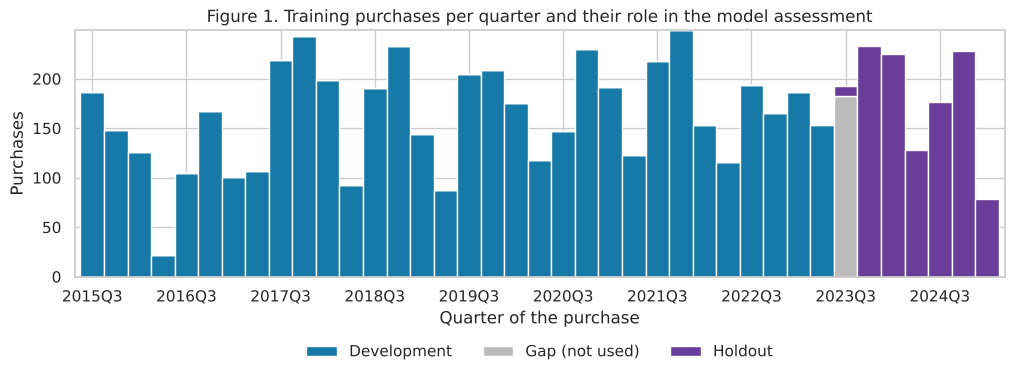

In [3]:
train = prep.prepare_purchases(raw_train)
development, holdout, inner_folds = prep.split_development_holdout(train)

# role of every training purchase in the model assessment
in_development = train["ID"].isin(development["ID"])
in_holdout = train["ID"].isin(holdout["ID"])
role = np.select([in_development, in_holdout], ["Development", "Holdout"], "Gap (not used)")
quarters = pd.DataFrame({"quarter": pd.PeriodIndex(train["purchase_date"], freq="Q"), "role": role})
per_quarter = quarters.groupby(["quarter", "role"]).size().unstack(fill_value=0)
per_quarter = per_quarter[["Development", "Gap (not used)", "Holdout"]]
per_quarter.index = per_quarter.index.astype(str)

ax = per_quarter.plot(kind="bar", stacked=True, width=1.0, figsize=(12, 3.2),
                      color=[PLOT_BLUE, "#BBBBBB", PLOT_PURPLE])
ax.set_xticks(range(0, len(per_quarter), 4))
ax.set_xticklabels(per_quarter.index[::4], rotation=0)
ax.set(title="Figure 1. Training purchases per quarter and their role in the model assessment",
       xlabel="Quarter of the purchase", ylabel="Purchases")
ax.legend(title="", ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False)
plt.show()

In [4]:
dev_dates = pd.to_datetime(development["purchase_date"])
holdout_dates = pd.to_datetime(holdout["purchase_date"])

# no fold may look into the future: every 90-day target window ends before the validation starts
for train_idx, val_idx in inner_folds:
    assert dev_dates.iloc[train_idx].max() + pd.Timedelta(days=90) < dev_dates.iloc[val_idx].min()
assert dev_dates.max() + pd.Timedelta(days=90) < holdout_dates.min()
assert not development["ID"].isin(holdout["ID"]).any()

fold_rows = []
for train_idx, val_idx in inner_folds:
    known = development["customer_id"].iloc[val_idx].isin(development["customer_id"].iloc[train_idx])
    fold_rows.append({
        "Training rows": len(train_idx),
        "Validation period": f"{dev_dates.iloc[val_idx].min():%b %Y} to {dev_dates.iloc[val_idx].max():%b %Y}",
        "Repeat rate": round(development[TARGET].iloc[val_idx].mean(), 3),
        "Known customers": round(known.mean(), 3),
    })
display(pd.DataFrame(fold_rows, index=pd.RangeIndex(1, 5, name="Inner fold")))
n_gap = len(train) - len(development) - len(holdout)
holdout_known = holdout["customer_id"].isin(development["customer_id"]).mean()
print(f"Development: {len(development)} rows, gap: {n_gap} rows, holdout: {len(holdout)} rows")
print(f"Holdout: {holdout_dates.min():%Y-%m-%d} to {holdout_dates.max():%Y-%m-%d}, "
      f"repeat rate {holdout[TARGET].mean():.3f}, known customers {holdout_known:.3f}")

,Training rows,Validation period,Repeat rate,Known customers
Inner fold,,,,
1,932,Aug 2017 to Dec 2018,0.591,0.631
2,1885,Dec 2018 to Jul 2020,0.530,0.770
3,2992,Jul 2020 to Nov 2021,0.581,0.850
4,3903,Nov 2021 to Jun 2023,0.510,0.871


Development: 5207 rows, gap: 184 rows, holdout: 1078 rows
Holdout: 2023-09-25 to 2025-02-15, repeat rate 0.604, known customers 0.877


<h3>Model assessment approach</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>Holdout by time</b>: the newest 1,078 purchases (Sep 2023 to Feb 2025) are used once, for the final model</li>
  <li><b>Cross-validation by time</b>: every decision is taken on the same 4 time folds of the development part (train on the past, validate on the next period, 1,041 rows each)</li>
  <li><b>90-day gap</b>: a training row stays only if its 90-day target window ends before the validation period starts, otherwise its label would contain validation purchases. The asserts above check every fold and the holdout. The 184 grey purchases are left out for this reason only; the Kaggle model uses all rows</li>
  <li><b>Why not a random split or LOO</b>: it would train on later purchases of the same customers. In the later periods 63% to 88% of the rows come from customers already seen in training, so known customers at a later time is the case to test</li>
  <li>Candidates are compared by the mean ± standard deviation of their F1 on the same 4 folds (Notebook 2)</li>
</ul>

</div>

<a id="exploration"></a>

<h1>II. Data Exploration and Preprocessing</h1>

<h2>Description of data received</h2>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>train.csv has 39 columns: ID, customer_id, the target and 36 further columns (current invoice, purchase history, rolling windows, categories, date, random_noise). clientes.csv has one row per customer. We only show what leads to a decision.</p>

</div>

<h3>1. Observations</h3>

In [5]:
# size of the data, rows per customer and time period
rows_per_customer = raw_train.groupby("customer_id").size()
top_10_share = rows_per_customer.nlargest(10).sum() / len(raw_train)
train_dates = pd.to_datetime(raw_train["purchase_date"])
has_history = raw_train["prior_purchase_count"] > 0

print(f"Rows in train: {len(raw_train)}")
print(f"Customers in train: {raw_train['customer_id'].nunique()}, "
      f"median rows per customer: {rows_per_customer.median():.0f}, "
      f"most rows of one customer: {rows_per_customer.max()}")
print(f"Share of rows from the 10 biggest customers: {top_10_share:.1%}")
print(f"Train period: {train_dates.min():%Y-%m-%d} to {train_dates.max():%Y-%m-%d}")
share_with_history = has_history.sum() / raw_train["purchase_date"].notna().sum()
print(f"Purchases of customers who bought before: {share_with_history:.1%}")
print(f"Repeat rate in train: {raw_train[TARGET].mean():.3f}")

# duplicated purchases
has_date = raw_train["purchase_date"].notna()
print(f"ID unique: {raw_train['ID'].is_unique}, "
      f"identical rows without the ID: {raw_train[has_date].drop(columns='ID').duplicated().sum()}, "
      f"rows with the same customer and date: "
      f"{raw_train[has_date].duplicated(['customer_id', 'purchase_date']).sum()}")

Rows in train: 6534
Customers in train: 610, median rows per customer: 4, most rows of one customer: 277
Share of rows from the 10 biggest customers: 17.5%
Train period: 2015-07-11 to 2025-02-15
Purchases of customers who bought before: 90.7%
Repeat rate in train: 0.559
ID unique: True, identical rows without the ID: 0, rows with the same customer and date: 0


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>Only 610 customers (median 4 rows, one has 277) --> rows of one customer are not independent</li>
  <li><b>No duplicates</b>: ID is unique, no two rows are identical without it, no customer has two rows on one date</li>
  <li>90.7% of the purchases come from customers who bought before --> the model mostly predicts known customers</li>
  <li>55.9% of the purchases are followed by a repeat --> accuracy says little, and the F1 baseline is high</li>
</ul>

</div>

<h3>2. Missing values</h3>

In [6]:
feature_columns = [col for col in raw_train.columns if col not in ["ID", "customer_id", TARGET]]
is_empty = raw_train[feature_columns].isna().all(axis=1)
filled_train = raw_train[~is_empty]

# share of missing values by the number of earlier purchases
prior_group = filled_train["prior_purchase_count"].clip(upper=3).astype(int).astype(str)
prior_group = prior_group.replace("3", "3+")
gap_columns = ["days_since_previous_purchase", "prior_std_purchase_value", "prior_mean_gap_days",
               "prior_std_gap_days", "spend_365d", "payment_type"]
missing_share = filled_train[gap_columns].isna().groupby(prior_group).mean().T.round(3)
display(missing_share.rename_axis("Share missing").rename_axis("Earlier purchases", axis=1))

is_first = filled_train["prior_purchase_count"] == 0
print(f"Rows without any feature value: {is_empty.sum()}, "
      f"their repeat rate: {raw_train.loc[is_empty, TARGET].mean():.3f}")
print(f"Repeat rate of first purchases: {filled_train.loc[is_first, TARGET].mean():.3f}, "
      f"of all other purchases: {filled_train.loc[~is_first, TARGET].mean():.3f}")

Earlier purchases,0,1,2,3+
Share missing,,,,
days_since_previous_purchase,1.000,0.043,0.055,0.030
prior_std_purchase_value,1.000,1.000,0.000,0.000
prior_mean_gap_days,1.000,1.000,0.058,0.034
prior_std_gap_days,1.000,1.000,1.000,0.000
spend_365d,0.030,0.043,0.041,0.028
payment_type,0.032,0.013,0.030,0.031


Rows without any feature value: 65, their repeat rate: 0.508
Repeat rate of first purchases: 0.333, of all other purchases: 0.583


In [7]:
# are the random gaps linked to the target? purchases with 3 or more earlier purchases have no structural gaps
full_history = filled_train[filled_train["prior_purchase_count"] >= 3]
gap_tests = {}
for col in feature_columns:
    is_missing = full_history[col].isna()
    if is_missing.any():
        p_value = chi2_contingency(pd.crosstab(is_missing, full_history[TARGET]))[1]
        gap_tests[col] = {"Missing rows": is_missing.sum(),
                          "Repeat rate if missing": full_history.loc[is_missing, TARGET].mean(),
                          "Repeat rate otherwise": full_history.loc[~is_missing, TARGET].mean(),
                          "p-value (chi-square)": p_value}
pd.DataFrame.from_dict(gap_tests, orient="index").round(3).rename_axis("Variable")

,Missing rows,Repeat rate if missing,Repeat rate otherwise,p-value (chi-square)
Variable,,,,
days_since_previous_purchase,154,0.636,0.614,0.634
prior_mean_purchase_value,163,0.613,0.615,1.000
prior_mean_gap_days,174,0.684,0.612,0.067
spend_365d,143,0.643,0.614,0.531
payment_type,159,0.610,0.615,0.968
salesperson,140,0.664,0.613,0.257
transport_method,143,0.629,0.614,0.781
warehouse,150,0.733,0.611,0.003


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight and decision</b></p>
<ul>
  <li>65 rows have no feature value and a repeat rate close to the average (0.508) --> dropped from train only; rows of a new file are never dropped</li>
  <li>History gaps are <b>structural</b>: a first purchase has no history, a second no standard deviation, a third no standard deviation of gaps. First purchases repeat in 33.3% of cases against 58.3% --> these cells get 0 plus two flags instead of a median</li>
  <li>The other gaps (about 3% per column) are not linked to the target (chi-square p of 0.067 or more) --> training median or level "missing", fitted inside the pipeline</li>
  <li>Only a missing <b>warehouse</b> goes with more repeats (73.3% against 61.1%, p = 0.003) --> a flag is tested in Section III</li>
</ul>

</div>

<h3>3. Implausible values</h3>

In [8]:
# number of rows with each kind of impossible value
def count_problems(purchases):
    prior_spend = purchases["prior_total_spend"]
    expected_mean = prior_spend / purchases["prior_purchase_count"]
    mean_error = (purchases["prior_mean_purchase_value"] - expected_mean).abs()
    return pd.Series({
        "Placeholder 1e9": ((purchases["prior_mean_purchase_value"] >= 1e8)
                            | (purchases["spend_365d"] >= 1e8)).sum(),
        "Negative amount": ((purchases["prior_mean_purchase_value"] < 0)
                            | (purchases["spend_365d"] < 0)).sum(),
        "Day code -4": ((purchases["days_since_previous_purchase"] < 0)
                        | (purchases["prior_mean_gap_days"] < 0)).sum(),
        "Mean differs from total / count": (mean_error > 0.02).sum(),
        "Maximum above total spend": (purchases["prior_max_purchase_value"] > prior_spend + 0.01).sum(),
        "spend_365d above total spend": ((purchases["spend_365d"] > prior_spend + 0.01)
                                         & (purchases["spend_365d"] < 1e8)).sum(),
    })


pd.DataFrame({
    "Train before the repair": count_problems(filled_train),
    "Train after the repair": count_problems(prep.repair_values(filled_train)),
}).rename_axis("Problem")

,Train before the repair,Train after the repair
Problem,,
Placeholder 1e9,31,0
Negative amount,31,0
Day code -4,32,0
Mean differs from total / count,78,0
Maximum above total spend,45,0
spend_365d above total spend,39,0


In [9]:
# can the wrong values be recomputed from other columns?
negative_mean = filled_train["prior_mean_purchase_value"] < 0
correct_mean = filled_train["prior_total_spend"] / filled_train["prior_purchase_count"]
sign_flipped = np.isclose(-filled_train.loc[negative_mean, "prior_mean_purchase_value"],
                          correct_mean[negative_mean])
net_plus_tax = filled_train["Total Liquido"] + filled_train["Total Imp_"]
gross_minus_discounts = (filled_train["Total Bruto"] - filled_train["Total Desc_ Linha"]
                         - filled_train["Total Desc_ Global"])
payable_rule = (filled_train["Total a Pagar"] - net_plus_tax).abs() < 0.02
net_rule = (filled_train["Total Liquido"] - gross_minus_discounts).abs() < 0.02

print(f"Negative means that are the correct mean with a minus: {sign_flipped.mean():.0%}")
print(f"Rows with Total a Pagar = Total Liquido + Total Imp_: {payable_rule.mean():.0%}")
print(f"Rows with Total Liquido = Total Bruto - discounts: {net_rule.mean():.0%}")

Negative means that are the correct mean with a minus: 100%
Rows with Total a Pagar = Total Liquido + Total Imp_: 100%
Rows with Total Liquido = Total Bruto - discounts: 100%


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight and decision (function repair_values)</b></p>
<ul>
  <li><b>prior_mean_purchase_value</b> (placeholder, negative or wrong in 78 rows) --> recomputed as total spend / count; every negative mean is the correct mean with a minus</li>
  <li><b>Day code -4</b> (32 values) --> missing, it is a code and not a duration</li>
  <li><b>prior_max_purchase_value</b> above the total spend (45 rows) --> missing, it cannot be recomputed</li>
  <li><b>spend_365d</b> --> placeholder to missing, sign removed, values above the total to missing</li>
  <li><b>Total a Pagar</b>, <b>Total Bruto</b> --> not used: they are exact sums of other columns in 100% of the rows</li>
</ul>

</div>

<h3>4. Skewed amounts and outliers</h3>

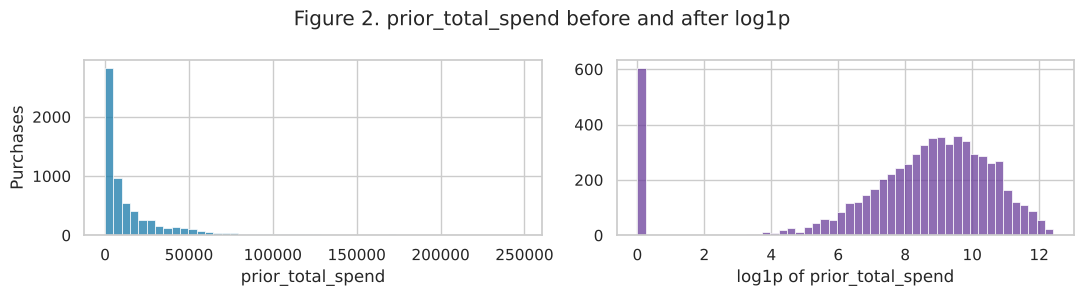

Median absolute skew: 3.75, after log1p: 0.74
Rows above the IQR bound: 642, their repeat rate: 0.841, repeat rate of the other rows: 0.529


In [10]:
repaired_train = prep.repair_values(filled_train)
skew_before = repaired_train[prep.SUPPLIED_NUMERIC].skew()
skew_after = np.log1p(repaired_train[prep.SUPPLIED_NUMERIC].clip(lower=0)).skew()

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
sns.histplot(repaired_train["prior_total_spend"], bins=50, color=PLOT_BLUE, ax=axes[0])
axes[0].set(xlabel="prior_total_spend", ylabel="Purchases")
sns.histplot(np.log1p(repaired_train["prior_total_spend"]), bins=50, color=PLOT_PURPLE, ax=axes[1])
axes[1].set(xlabel="log1p of prior_total_spend", ylabel="")
fig.suptitle("Figure 2. prior_total_spend before and after log1p")
plt.tight_layout()
plt.show()

# IQR rule on the total spend: are the outliers errors or big customers?
q1, q3 = repaired_train["prior_total_spend"].quantile([0.25, 0.75])
is_outlier = repaired_train["prior_total_spend"] > q3 + 1.5 * (q3 - q1)
print(f"Median absolute skew: {skew_before.abs().median():.2f}, "
      f"after log1p: {skew_after.abs().median():.2f}")
print(f"Rows above the IQR bound: {is_outlier.sum()}, their repeat rate: "
      f"{filled_train.loc[is_outlier, TARGET].mean():.3f}, repeat rate of the other rows: "
      f"{filled_train.loc[~is_outlier, TARGET].mean():.3f}")

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight and decision</b></p>
<ul>
  <li>Amounts, counts and days are right-skewed (median absolute skew 3.75, after log1p 0.74; Figure 2) --> log1p before scaling, inside the pipeline</li>
  <li>The 642 rows above the IQR bound of <b>prior_total_spend</b> are big customers, not errors: they repeat in 84.1% of cases against 52.9% --> kept. Capping them is tested in Section III</li>
</ul>

</div>

<h3>5. Relationship with the target</h3>

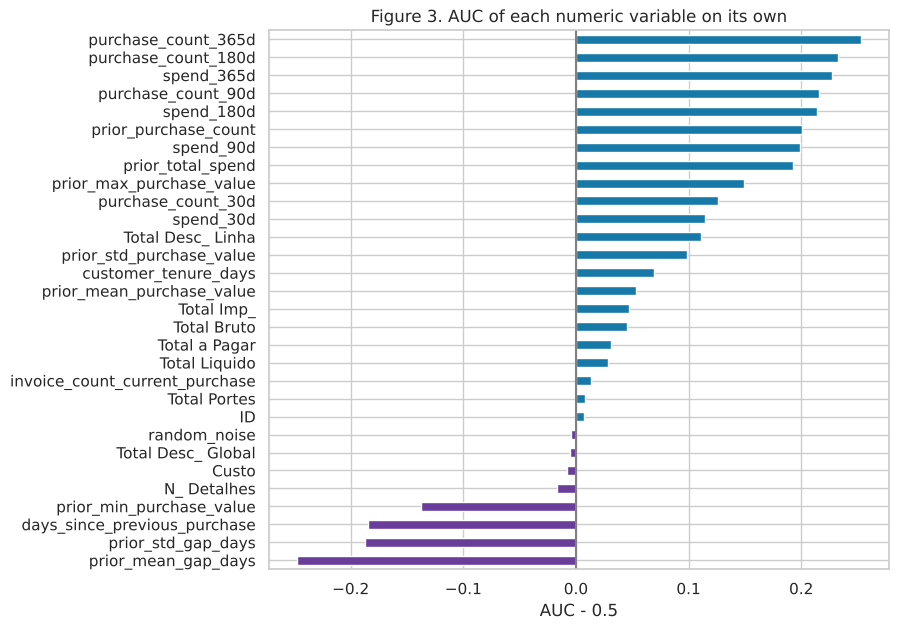

{'purchase_count_365d': 0.753, 'prior_mean_gap_days': 0.252, 'Total Liquido': 0.529, 'random_noise': 0.495, 'ID': 0.507}
Mutual information with the target: {'purchase_count_365d': 0.117, 'Total Liquido': 0.011, 'random_noise': 0.005, 'ID': 0.0}
Pairs with a Spearman correlation of 0.85 or more: 11


In [11]:
# AUC of every numeric column on its own: 0.5 means no signal,
# below 0.5 means "higher value, fewer repeats"
single_columns = prep.SUPPLIED_NUMERIC + ["Total a Pagar", "Total Bruto", "random_noise", "ID"]
single_auc = {}
for col in single_columns:
    has_value = repaired_train[col].notna()
    single_auc[col] = roc_auc_score(filled_train.loc[has_value, TARGET],
                                    repaired_train.loc[has_value, col])
single_auc = pd.Series(single_auc).sort_values()

colors = np.where(single_auc >= 0.5, PLOT_BLUE, PLOT_PURPLE)
ax = (single_auc - 0.5).plot(kind="barh", figsize=(8, 7), color=colors)
ax.axvline(0, color="grey")
ax.set(title="Figure 3. AUC of each numeric variable on its own", xlabel="AUC - 0.5", ylabel="")
plt.show()
examples = ["purchase_count_365d", "prior_mean_gap_days", "Total Liquido", "random_noise", "ID"]
print(single_auc[examples].round(3).to_dict())

# the AUC only sees monotonic relationships, mutual information sees any shape
benchmark_columns = ["purchase_count_365d", "Total Liquido", "random_noise", "ID"]
mutual_info = mutual_info_classif(repaired_train[benchmark_columns], filled_train[TARGET],
                                  random_state=prep.RANDOM_STATE)
print("Mutual information with the target:",
      pd.Series(mutual_info, index=benchmark_columns).round(3).to_dict())

# pairs of supplied numeric columns that are almost copies of each other
spearman = repaired_train[prep.SUPPLIED_NUMERIC].corr(method="spearman").abs()
upper_triangle = np.triu(np.ones(spearman.shape, dtype=bool), k=1)
print(f"Pairs with a Spearman correlation of 0.85 or more: {(spearman.where(upper_triangle) >= 0.85).sum().sum()}")

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>The strongest variables describe how often and how regularly a customer buys: <b>purchase_count_365d</b> (AUC 0.75), <b>prior_mean_gap_days</b> (0.25, i.e. short gaps --> more repeats). The current invoice says little (<b>Total Liquido</b> 0.53). Figure 3</li>
  <li><b>random_noise</b> (0.495) and <b>ID</b> (0.507) carry no signal, also not in a non-monotonic form (mutual information 0.005 and 0.000 against 0.117) --> ID is dropped, random_noise stays as a benchmark: a selection method that keeps it is not selective enough</li>
  <li>Many supplied columns are near copies (11 pairs with |Spearman| of 0.85 or more) --> the filter in Section III keeps the stronger one of each pair</li>
</ul>

</div>

<h3>6. Categorical variables and identifiers</h3>

In [12]:
# levels, biggest level, link with the target and customers per level of every category
category_columns = ["transport_method", "payment_type", "salesperson", "commercial_zone", "warehouse",
                    "document_series"]
category_check = {}
for col in category_columns:
    level_counts = filled_train[col].value_counts()
    crosstab = pd.crosstab(filled_train[col].fillna("missing"), filled_train[TARGET])
    customers_per_level = filled_train.groupby(col)["customer_id"].nunique()
    category_check[col] = {
        "Levels": len(level_counts),
        "Share of the biggest level": round(level_counts.iloc[0] / level_counts.sum(), 3),
        "Cramér's V with the target": round(association(crosstab, method="cramer"), 3),
        "Levels used by one customer only": (customers_per_level == 1).sum(),
    }
display(pd.DataFrame(category_check).T.rename_axis("Variable"))

series_periods = filled_train.groupby("document_series")["purchase_date"].agg(["min", "max"])
for series, period in series_periods.iterrows():
    print(f"{series}: purchases from {period['min']} to {period['max']}")

,Levels,Share of the biggest level,Cramér's V with the target,Levels used by one customer only
Variable,,,,
transport_method,80.0,0.178,0.285,40.0
payment_type,9.0,0.728,0.234,0.0
salesperson,9.0,0.646,0.201,0.0
commercial_zone,5.0,0.968,0.064,2.0
warehouse,2.0,0.997,0.040,0.0
document_series,3.0,0.423,0.003,0.0


Ctrl Z Series 1: purchases from 2017-04-05 to 2021-05-16
Ctrl Z Series 2: purchases from 2021-05-22 to 2025-02-15
Ctrl Z Series 3: purchases from 2015-07-11 to 2021-05-17


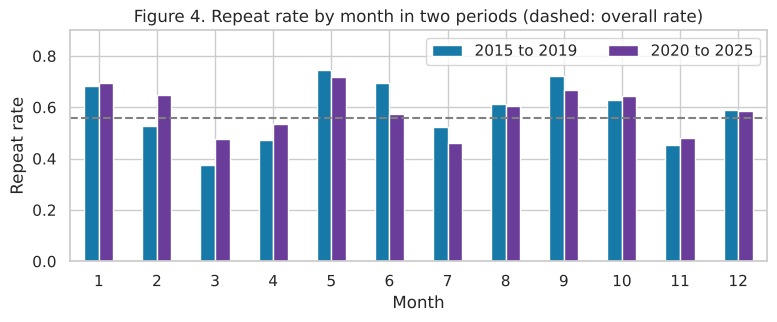

Correlation of the monthly pattern between the two periods: 0.81


In [13]:
# repeat rate per month in two periods
month = pd.to_datetime(filled_train["purchase_date"]).dt.month
is_early = pd.to_datetime(filled_train["purchase_date"]).dt.year <= 2019
rate_by_month = pd.DataFrame({
    "2015 to 2019": filled_train[is_early].groupby(month[is_early])[TARGET].mean(),
    "2020 to 2025": filled_train[~is_early].groupby(month[~is_early])[TARGET].mean(),
})
ax = rate_by_month.plot(kind="bar", figsize=(9, 3), color=[PLOT_BLUE, PLOT_PURPLE], rot=0)
ax.axhline(filled_train[TARGET].mean(), color="grey", linestyle="--")
ax.set(title="Figure 4. Repeat rate by month in two periods (dashed: overall rate)",
       xlabel="Month", ylabel="Repeat rate", ylim=(0, 0.9))
ax.legend(ncol=2, loc="upper right")
plt.show()
print(f"Correlation of the monthly pattern between the two periods: "
      f"{rate_by_month['2015 to 2019'].corr(rate_by_month['2020 to 2025']):.2f}")

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight and decision: identifier-like variables are checked before any model sees them</b></p>
<ul>
  <li><b>ID</b> --> dropped (one value per row). <b>customer_id</b> --> only for the history; as a feature it would memorise customers</li>
  <li><b>transport_method</b> --> dropped: 80 levels, 40 used by one customer only, so it is a hidden customer identifier</li>
  <li><b>commercial_zone</b> (96.8% one level), <b>warehouse</b> (99.7%) --> dropped</li>
  <li><b>document_series</b> --> dropped: no link with the target (V 0.003), and since May 2021 only Series 2 exists, so it is a time stamp</li>
  <li><b>payment_type</b>, <b>salesperson</b> --> candidates (9 levels each, V 0.23 and 0.20)</li>
  <li><b>purchase_date</b> --> only the month: its pattern is stable between 2015-2019 and 2020-2025 (correlation 0.81, Figure 4); the year of a later purchase is never seen in training</li>
</ul>

</div>

<h3>7. clientes.csv</h3>

In [14]:
# clientes.csv is joined to train through customer_id
with_clientes = filled_train.merge(clientes, on="customer_id", how="left")
print(f"Customers in clientes: {len(clientes)}, customer_id unique: {clientes['customer_id'].is_unique}")
print(f"Train customers found: {filled_train['customer_id'].isin(clientes['customer_id']).mean():.0%}, "
      f"rows before and after the join: {len(filled_train)} and {len(with_clientes)}")

Customers in clientes: 1143, customer_id unique: True
Train customers found: 100%, rows before and after the join: 6469 and 6469


In [15]:
# levels and share of missing values per customer attribute
pd.DataFrame({"levels": clientes.nunique(),
              "share missing": clientes.isna().mean().round(2)}).drop(index="customer_id")

,levels,share missing
country_or_region,11,0.00
commercial_region,37,0.10
island,10,0.51
municipality,183,0.14
city,417,0.48
postal_area,271,0.06
postal_code,828,0.15
street,511,0.52
address,1120,0.01
customer_type,0,1.00


In [16]:
# can the customer attributes be dated? compare them with the first purchase of each customer
first_year = pd.to_datetime(filled_train["purchase_date"]).groupby(filled_train["customer_id"]).min().dt.year
customers = clientes.set_index("customer_id").join(first_year.rename("first_year"), how="inner")
island_by_year = customers.groupby("first_year")["island"].apply(lambda island: island.notna().mean())
print(f"customer_since_year after the year of the first purchase: "
      f"{(customers['customer_since_year'] > customers['first_year']).sum()} of {len(customers)} customers")
print("Share of customers with a known island, by year of the first purchase:",
      island_by_year.round(2).to_dict())

customer_since_year after the year of the first purchase: 0 of 607 customers
Share of customers with a known island, by year of the first purchase: {2015: 0.52, 2016: 0.67, 2017: 0.56, 2018: 0.73, 2019: 0.67, 2020: 0.47, 2021: 0.35, 2022: 0.28, 2023: 0.48, 2024: 0.39, 2025: 0.33}


In [17]:
# train customers that share an address: one customer registered twice?
train_clients = clientes[clientes["customer_id"].isin(filled_train["customer_id"])]
purchase_period = pd.to_datetime(filled_train["purchase_date"]).groupby(filled_train["customer_id"]).agg(["min", "max"])
shared_address = (train_clients[train_clients.duplicated("address", keep=False)]
                  .join(purchase_period, on="customer_id").sort_values("min"))
by_address = shared_address.groupby("address")
starts_after = (by_address["min"].last() > by_address["max"].first()).sum()
print(f"Pairs of train customers with the same address: {by_address.ngroups}, "
      f"the later ID starts after the earlier one stops: {starts_after}")

Pairs of train customers with the same address: 10, the later ID starts after the earlier one stops: 5


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight and decision</b></p>
<ul>
  <li>Every train customer is in clientes.csv and customer_id is unique --> the join neither adds nor loses rows</li>
  <li><b>No clientes column is used.</b> clientes.csv is a snapshot: whether the island is known varies between 28% and 73% by the year of the first purchase, so address fields were filled in or updated later, and their value at the time of a purchase is unknown. <b>customer_type</b> is empty, names and addresses are almost unique, and <b>customer_since_year</b> is covered by <b>customer_tenure_days</b></li>
  <li>10 pairs of customers share an address; in 5 the later ID only starts after the earlier one stops --> probably registered twice, not merged without a reliable key (limitation, at most 10 of 610 customers)</li>
</ul>

</div>

<h2>Steps taken to clean and prepare the data based on exploration</h2>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>All row rules are functions in preprocessing.py and run in this order inside prepare_purchases. They are fixed rules that learn nothing from the data, so test.csv goes through the same functions in the deployment. Every step that learns from the data (median, scaling, one-hot levels) is part of the pipeline (Step 4).</p>
<ul>
  <li><b>drop_empty_rows</b>: drops the 65 empty training rows (Insight 2)</li>
  <li><b>repair_values</b>: recomputes or removes impossible values (Insight 3)</li>
  <li><b>add_customer_history</b>: four features from earlier purchases of the same customer (Step 3)</li>
  <li><b>fill_structural_gaps</b>: 0 and two flags where a history value cannot exist yet (Insight 2)</li>
  <li><b>add_row_features</b>: month, discount_rate, purchases_per_year, zero_cost (Step 2)</li>
</ul>

</div>

<h3>Step 1: the cleaning rules applied to train</h3>

In [18]:
# missing history values before and after the row rules
history_columns = list(prep.PURCHASES_NEEDED) + ["spend_365d"]
print(f"Missing history values in train: {filled_train[history_columns].isna().sum().sum()} before, "
      f"{train[history_columns].isna().sum().sum()} after the row rules")

Missing history values in train: 6698 before, 696 after the row rules


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>The structural fill removes most gaps. The rest are the random gaps and the repaired values, which are left to the median imputation inside the pipeline.</p>

</div>

<h3>Step 2: new features from the same row</h3>

In [19]:
# does a new feature say more than the column it is built from
built_from = {"discount_rate": "Total Desc_ Linha", "purchases_per_year": "purchase_count_365d",
              "zero_cost": "Custo"}
for new_feature, base_column in built_from.items():
    auc_new = roc_auc_score(train[TARGET], train[new_feature])
    auc_base = roc_auc_score(train[TARGET], train[base_column].fillna(0))
    print(f"{new_feature}: AUC {auc_new:.3f} (the column it is built from, {base_column}: {auc_base:.3f})")

has_zero_cost = train["zero_cost"] == 1
print(f"Repeat rate with a cost of 0: {train.loc[has_zero_cost, TARGET].mean():.2f}, "
      f"otherwise: {train.loc[~has_zero_cost, TARGET].mean():.2f}")

discount_rate: AUC 0.624 (the column it is built from, Total Desc_ Linha: 0.611)
purchases_per_year: AUC 0.744 (the column it is built from, purchase_count_365d: 0.753)
zero_cost: AUC 0.518 (the column it is built from, Custo: 0.492)
Repeat rate with a cost of 0: 0.68, otherwise: 0.55


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>discount_rate</b> separates the classes better than the absolute line discount (AUC 0.624 against 0.611) because it does not depend on the invoice size</li>
  <li><b>purchases_per_year</b> covers the whole customer lifetime instead of the last 365 days; <b>zero_cost</b> marks invoices with cost 0 (repeat rate 0.68 against 0.55)</li>
</ul>

</div>

<h3>Step 3: customer history</h3>

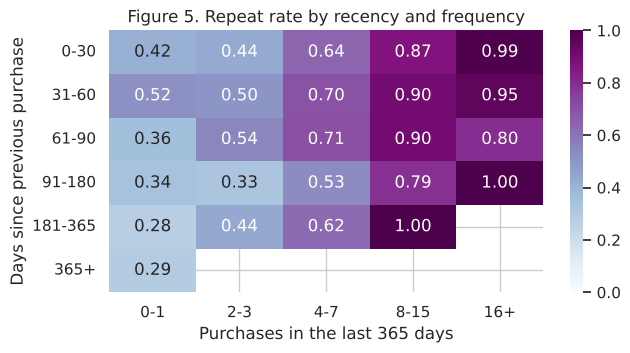

In [20]:
# repeat rate by recency (rows) and frequency (columns)
recency = pd.cut(repaired_train["days_since_previous_purchase"], [0, 30, 60, 90, 180, 365, 5000],
                 labels=["0-30", "31-60", "61-90", "91-180", "181-365", "365+"], include_lowest=True)
frequency = pd.cut(repaired_train["purchase_count_365d"], [-1, 1, 3, 7, 15, 500],
                   labels=["0-1", "2-3", "4-7", "8-15", "16+"])
repeat_rate = pd.crosstab(recency, frequency, values=filled_train[TARGET], aggfunc="mean")

fig, ax = plt.subplots(figsize=(7, 3.4))
sns.heatmap(repeat_rate, annot=True, fmt=".2f", cmap="BuPu", vmin=0, vmax=1, ax=ax)
ax.set(title="Figure 5. Repeat rate by recency and frequency", xlabel="Purchases in the last 365 days",
       ylabel="Days since previous purchase")
plt.show()

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p>In every row of Figure 5 the repeat rate rises with the number of purchases in the last year, so the customer's own rhythm matters at every recency. The supplied columns describe the past with counts, means and windows, but two things are missing: how reliably the customer has come back within 90 days so far, and whether the customer usually buys in this season.</p>
<ul>
  <li><b>prior_repeat_share</b>: share of the customer's earlier purchases that were followed by another purchase within 90 days</li>
  <li><b>recent_repeat_share</b>: the same for the last 5 earlier purchases</li>
  <li><b>same_season_last_year</b>, <b>same_season_two_years_ago</b>: purchases of the customer in the 90 days after the same calendar date one and two years ago. 90 days is the window of the target, so these features ask whether the customer bought in exactly this window before</li>
  <li>Each row only uses purchases of the same customer up to its own date</li>
</ul>

</div>

In [21]:
# customer history features: AUC on their own and overlap with purchase_count_365d
for feature in prep.CUSTOMER_HISTORY:
    rho = train[feature].corr(train["purchase_count_365d"], method="spearman")
    print(f"{feature}: AUC on its own {roc_auc_score(train[TARGET], train[feature]):.3f}, "
          f"Spearman with purchase_count_365d {rho:.2f}")

prior_repeat_share: AUC on its own 0.743, Spearman with purchase_count_365d 0.72
recent_repeat_share: AUC on its own 0.741, Spearman with purchase_count_365d 0.76
same_season_last_year: AUC on its own 0.686, Spearman with purchase_count_365d 0.73
same_season_two_years_ago: AUC on its own 0.642, Spearman with purchase_count_365d 0.50


In [22]:
# leakage check: no feature of a row may change when every later purchase is deleted
derived_columns = prep.CUSTOMER_HISTORY + prep.ROW_FEATURES + prep.STRUCTURAL_FLAGS + prep.ROW_FLAGS
raw_dates = pd.to_datetime(raw_train["purchase_date"])
changed_values = 0
cutoffs = pd.date_range("2016-01-01", "2025-02-15", freq="90D")
check_started = time.perf_counter()
for cutoff in tqdm(cutoffs, desc="cut-offs", leave=True, position=0):
    until_cutoff = prep.prepare_purchases(raw_train[raw_dates <= cutoff].reset_index(drop=True))
    both = until_cutoff.merge(train, on="ID", suffixes=("_cut", "_all"))
    for col in derived_columns:
        changed_values += (~np.isclose(both[f"{col}_cut"], both[f"{col}_all"])).sum()
print(f"Cut-offs tested: {len(cutoffs)}, feature values that change: {changed_values}, "
      f"{time.perf_counter() - check_started:.1f} seconds")

# the supplied 90-day count against the earlier train purchases of the same customer
ordered = train.assign(day=pd.to_datetime(train["purchase_date"])).sort_values(["customer_id", "day"])
earlier_90d = []
for _, purchases in ordered.groupby("customer_id"):
    days = purchases["day"].to_numpy()
    earlier_90d += [((days >= day - np.timedelta64(90, "D")) & (days < day)).sum() for day in days]
same_count = (ordered["purchase_count_90d"].to_numpy() == np.array(earlier_90d)).mean()
print(f"purchase_count_90d equals the number of earlier train purchases in 90 days: {same_count:.1%}")

Cut-offs tested: 38, feature values that change: 0, 4.6 seconds
purchase_count_90d equals the number of earlier train purchases in 90 days: 98.7%


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<p><b>Insight</b></p>
<ul>
  <li>Each history feature separates the classes on its own (AUC 0.64 to 0.74) and is no copy of <b>purchase_count_365d</b> (Spearman 0.50 to 0.76)</li>
  <li><b>No look into the future</b>: with every purchase after a cut-off deleted, no row or history feature of the remaining rows changes at any of the 38 cut-offs</li>
</ul>

</div>

<h3>Leakage review of all candidate variables</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>Current invoice</b>: the purchase itself --> no risk</li>
  <li><b>Supplied history and windows</b>: <b>purchase_count_90d</b> equals the number of earlier train purchases in 98.7% of the rows; the rest are purchases outside train.csv --> past only</li>
  <li><b>Row features and customer history</b>: checked above</li>
  <li><b>clientes.csv</b>: not used (snapshot, Insight 7)</li>
  <li><b>Target</b>: looks 90 days ahead --> 90-day gap in every split (Section I)</li>
</ul>

</div>

<h3>Step 4: the pre-processing pipeline</h3>

In [23]:
# transformer fitted on the development part and applied to the holdout
numeric = prep.SUPPLIED_NUMERIC + prep.ROW_FEATURES + prep.CUSTOMER_HISTORY
flags = prep.STRUCTURAL_FLAGS + prep.ROW_FLAGS
categorical = prep.PURCHASE_CATEGORIES

preprocessor = prep.build_preprocessor(numeric, flags, categorical)
dev_matrix = preprocessor.fit_transform(development)
holdout_matrix = preprocessor.transform(holdout)
encoded_names = preprocessor.get_feature_names_out()
encoded_variables = [prep.source_variable(name, categorical) for name in encoded_names]
columns_per_variable = pd.Series(encoded_variables).value_counts()

print(f"Candidate variables: {len(numeric)} numeric, {len(flags)} flags, {len(categorical)} categorical")
print(f"Development matrix: {dev_matrix.shape}, missing values: {np.isnan(dev_matrix).sum()}")
print(f"Holdout matrix: {holdout_matrix.shape}, missing values: {np.isnan(holdout_matrix).sum()}")
print("One-hot columns:", columns_per_variable[categorical].to_dict())

Candidate variables: 32 numeric, 3 flags, 3 categorical
Development matrix: (5207, 61), missing values: 0
Holdout matrix: (1078, 61), missing values: 0
One-hot columns: {'payment_type': 6, 'salesperson': 8, 'month': 12}


<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li><b>build_preprocessor</b>: numbers get the training median, log1p and the StandardScaler (shares only scaled), flags pass through, categories get "missing" and one-hot encoding with levels under 30 rows grouped</li>
  <li>The 38 candidate variables become 61 columns without missing values; the holdout gets the same columns because the transformer is fitted on earlier rows only</li>
</ul>

</div>

<h3>Step 5: save the prepared data</h3>

In [24]:
# save the prepared training purchases for notebooks 2 and 3
Path("../data/interim").mkdir(parents=True, exist_ok=True)
train.to_csv("../data/interim/purchases_train.csv", index=False)

saved_train = prep.load_interim("../data/interim")
print(f"Saved {len(train)} prepared training purchases with {train.shape[1]} columns")
print("Read back without any difference:", train.compare(saved_train).empty)

Saved 6469 prepared training purchases with 49 columns
Read back without any difference: True


<h3>Conclusion of Section II</h3>

<div style="background-color:#e6f2fb; padding:20px 24px; border-radius:0;">

<ul>
  <li>Five row rules clean train.csv; test.csv runs through the same rules in the deployment</li>
  <li>The signal sits in the purchase rhythm of a customer; the current invoice adds little</li>
  <li>Section III decides which of the 38 candidates stay and tests the preprocessing choices</li>
  <li><b>Limitation</b>: customer_id is not a perfect key (at most 10 of 610 customers registered twice)</li>
</ul>

</div>